# Links 
github repo: https://github.com/vildeskobba/IND320vilde 

Streamlit app: https://ind320vilde.streamlit.app/ 

Panopto_video: 


In [29]:
%pip install -q -r requirements.txt


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import geopandas as gpd 
import pandas as pd

In [3]:
# read shapefile 
nve_region = gpd.read_file('data_nve/NVE_Region/NVE_Region.shp')
budomrader = gpd.read_file('data_nve/Budområder/Budområder.shp') 

# Inspect electricity areas
print("BUDOMRÅDER:")
print(budomrader.columns)
print(budomrader.head())

# Inspect NVE regions
print("\nNVE REGION:")
print(nve_region.columns)
print(nve_region.head())

BUDOMRÅDER:
Index(['objectid', 'budomr', 'globalid', 'st_area(sh', 'st_perimet',
       'geometry'],
      dtype='str')
   objectid budomr  globalid    st_area(sh    st_perimet  \
0       1.0   NO 1       NaN  6.052902e+10  1.657761e+06   
1       2.0   NO 2       NaN  6.875969e+10  1.256473e+06   
2       3.0   NO 3       NaN  1.042199e+11  1.773323e+06   
3       4.0   NO 4       NaN  2.032500e+11  3.385499e+06   
4       5.0   NO 5       NaN  3.334870e+10  1.106762e+06   

                                            geometry  
0  POLYGON ((337473.63 6970542.97, 337711.9 69703...  
1  POLYGON ((-9833.91 6726499.86, -9836 6726404.0...  
2  POLYGON ((308588.7 7261519.43, 313576.63 72590...  
3  POLYGON ((973920.93 7962739.19, 974922.77 7962...  
4  POLYGON ((101466.43 6881318.54, 101525.43 6881...  

NVE REGION:
Index(['OBJECTID', 'REGION', 'REGIONNAVN', 'POSTNUMMER', 'POSTSTED',
       'BESÃKSADR', 'ADRESSE', 'geometry'],
      dtype='str')
   OBJECTID REGION         REGIONNAVN POSTN

In [4]:
#generate k random points in each budområde 
K = 1000
points_per_bo = budomrader['geometry'].sample_points(size=K, random_state=42) 

# transform to lat and lon format 
bo_points_wgs84 = points_per_bo.to_crs(epsg=4326)

omrade_koord = {}

for idx, multipoint in bo_points_wgs84.items(): 
    budomrade_navn = budomrader.loc[idx, 'budomr'].replace(' ', '_')
    for point in multipoint.geoms: 
        lat = point.y 
        lon = point.x 

    df = pd.DataFrame(
        [(point.x, point.y) for point in multipoint.geoms],
        columns=["longitude", "latitude"]
    )
    omrade_koord[budomrade_navn] = df

for key, value in omrade_koord.items(): 
    print(key) 
    print(value.head())
    print(f'type: {type(value)}, shape: {value.shape}')
    


NO_1
   longitude   latitude
0  12.070913  59.955000
1  12.542545  60.385653
2   8.625358  61.040894
3  11.096709  59.131569
4  10.761743  59.093862
type: <class 'pandas.DataFrame'>, shape: (1000, 2)
NO_2
   longitude   latitude
0   7.430003  59.750189
1   9.934589  59.342925
2   7.430609  59.976603
3   6.549410  59.033861
4   5.344975  58.783737
type: <class 'pandas.DataFrame'>, shape: (1000, 2)
NO_3
   longitude   latitude
0  10.392955  62.496550
1   9.349717  62.570267
2  10.924940  63.125835
3   4.733227  61.792717
4   4.472204  60.909073
type: <class 'pandas.DataFrame'>, shape: (1000, 2)
NO_4
   longitude   latitude
0  18.005215  69.377215
1  21.297309  70.722808
2  25.308629  71.123717
3  18.810911  68.823286
4  23.179847  68.740724
type: <class 'pandas.DataFrame'>, shape: (1000, 2)
NO_5
   longitude   latitude
0   7.082139  60.814731
1   8.549308  60.904123
2   9.486195  60.329634
3   4.691453  60.414732
4   7.074609  61.091951
type: <class 'pandas.DataFrame'>, shape: (1000, 2)


In [7]:
from utils.APIs.METEO_API import download_weather 

response_df = download_weather(
    coordinates=omrade_koord, 
    region="NO_3",     
    start_date="2024-01-01",
    end_date="2024-12-31", 
    batch_size=100
    )

starting download of hourly data for NO_3 between 2024-01-01 and 2024-12-31...
Downloaded 100/1000 locations
Downloaded 200/1000 locations
Downloaded 300/1000 locations
Downloaded 400/1000 locations
Downloaded 500/1000 locations
Downloaded 600/1000 locations
Downloaded 700/1000 locations
Downloaded 800/1000 locations


KeyboardInterrupt: 

In [9]:
display(response_df.head())
print(response_df.shape)

,time,latitude,longitude,temperature,precipitation
0,2024-01-01 00:00:00+01:00,62.49655,10.392955,-9.6335,0.0
1,2024-01-01 01:00:00+01:00,62.49655,10.392955,-9.5335,0.0
2,2024-01-01 02:00:00+01:00,62.49655,10.392955,-9.4335,0.0
3,2024-01-01 03:00:00+01:00,62.49655,10.392955,-9.2835,0.0
4,2024-01-01 04:00:00+01:00,62.49655,10.392955,-9.1335,0.0


(48000, 5)


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.fft import dct, idct


def plot_precipitation_outliers(
    weather_data,
    cutoff=30,
    n_std=3
):
    """
    Plot average precipitation and identify outliers using
    high-pass DCT filtering and robust SPC boundaries.

    Parameters
    ----------
    weather_data : DataFrame
        Must contain time, precipitation, latitude and longitude.
    cutoff : int
        Number of low-frequency DCT coefficients to remove.
    n_std : float
        Number of robust standard deviations for SPC boundaries.

    Returns
    -------
    fig : matplotlib Figure
    outlier_summary : DataFrame
    """

    # Average precipitation across all locations
    precipitation = (
        weather_data.groupby("time")["precipitation"]
        .mean()
        .sort_index()
    )

    x = precipitation.to_numpy()

    # DCT high-pass filtering
    coefficients = dct(x, norm="ortho")
    coefficients[:cutoff] = 0

    satv = idct(coefficients, norm="ortho")

    # Robust statistics
    median = np.median(satv)
    mad = np.median(np.abs(satv - median))

    robust_std = 1.4826 * mad

    upper = median + n_std * robust_std
    lower = median - n_std * robust_std

    # Identify outliers
    outliers = (satv > upper) | (satv < lower)

    # Plot original precipitation
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        precipitation.index,
        x,
        label="Average precipitation",
        linewidth=0.8
    )

    ax.scatter(
        precipitation.index[outliers],
        x[outliers],
        color="red",
        label="Outliers",
        zorder=3
    )

    ax.set_title("Average precipitation and detected outliers")
    ax.set_xlabel("Time")
    ax.set_ylabel("Precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # Outlier summary
    outlier_summary = pd.DataFrame({
        "time": precipitation.index[outliers],
        "precipitation": x[outliers],
        "SATV": satv[outliers]
    })

    return fig, outlier_summary

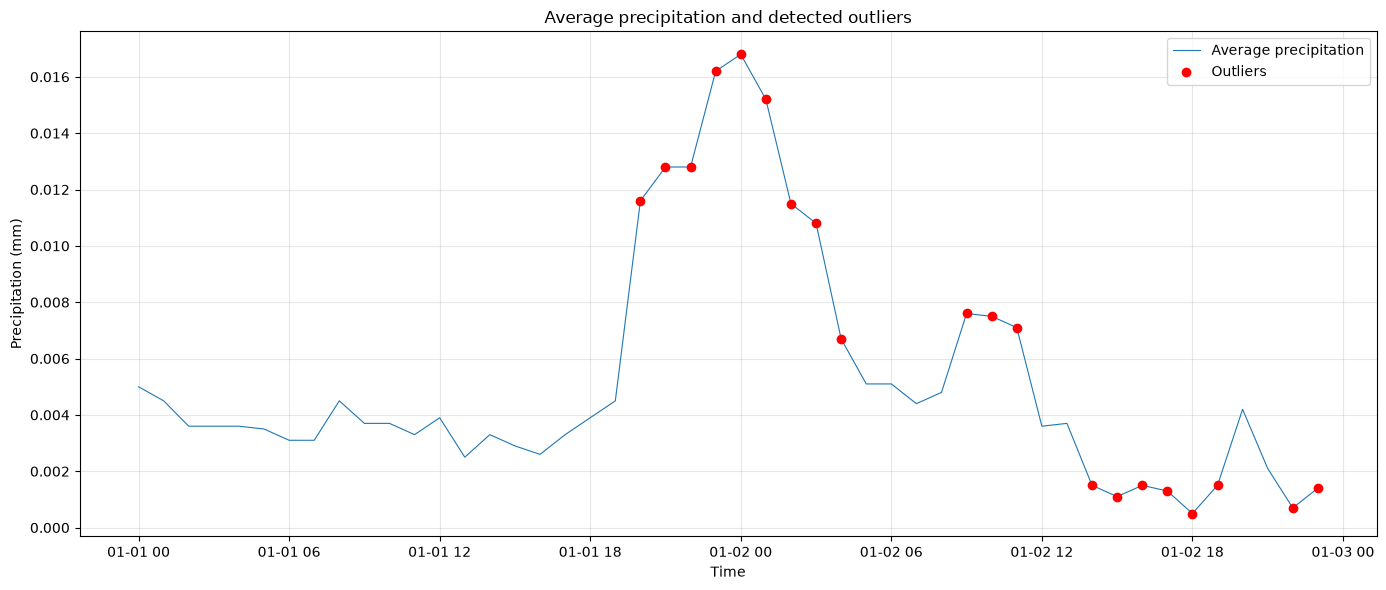

                       time  precipitation      SATV
0 2024-01-01 20:00:00+01:00         0.0116  0.006367
1 2024-01-01 21:00:00+01:00         0.0128  0.007567
2 2024-01-01 22:00:00+01:00         0.0128  0.007567
3 2024-01-01 23:00:00+01:00         0.0162  0.010967
4 2024-01-02 00:00:00+01:00         0.0168  0.011567
Number of outliers: 20


In [16]:
fig, outliers = plot_precipitation_outliers(
    response_df,
    cutoff=1,
    n_std=1
)

plt.show()

print(outliers.head())
print("Number of outliers:", len(outliers))

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import LocalOutlierFactor


def plot_temperature_anomalies(weather_data, contamination=0.01, n_neighbors=20):
    # Calculate average temperature across locations
    temperature = (
        weather_data.groupby("time")["temperature"]
        .mean()
        .sort_index()
        .dropna()
    )

    # LOF expects a 2D array
    X = temperature.to_numpy().reshape(-1, 1)

    # Detect anomalies
    lof = LocalOutlierFactor(
        n_neighbors=n_neighbors,
        contamination=contamination
    )
    predictions = lof.fit_predict(X)
    anomaly_mask = predictions == -1

    # Plot
    fig, ax = plt.subplots(figsize=(14, 6))

    ax.plot(
        temperature.index,
        temperature,
        label="Average temperature",
        linewidth=0.8
    )

    ax.scatter(
        temperature.index[anomaly_mask],
        temperature[anomaly_mask],
        color="red",
        label="Anomalies (LOF)",
        zorder=3
    )

    ax.set_title("Average temperature and detected anomalies")
    ax.set_xlabel("Time")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    ax.grid(alpha=0.3)

    plt.tight_layout()

    # Summarise anomalies
    anomaly_summary = pd.DataFrame({
        "time": temperature.index[anomaly_mask],
        "temperature": temperature[anomaly_mask],
        "LOF score": lof.negative_outlier_factor_[anomaly_mask]
    })

    return fig, anomaly_summary

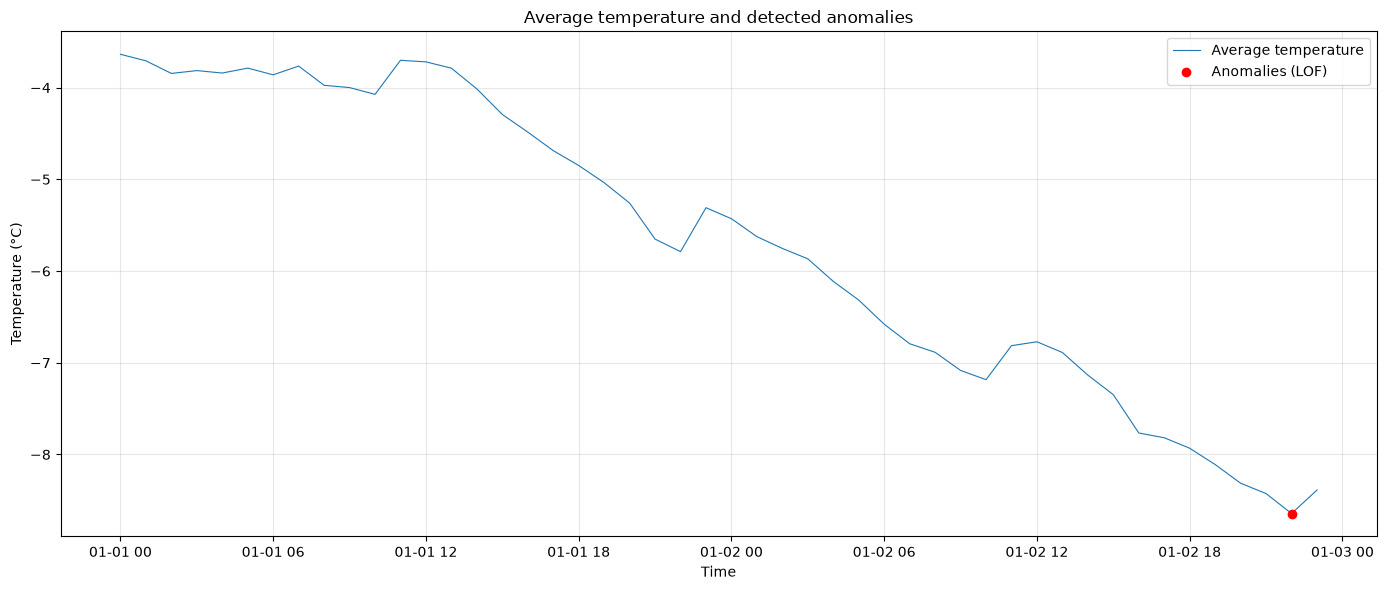

                                               time  temperature  LOF score
time                                                                       
2024-01-02 22:00:00+01:00 2024-01-02 22:00:00+01:00    -8.644297  -1.284646
Number of anomalies: 1


In [18]:
fig, anomalies = plot_temperature_anomalies(
    response_df,
    contamination=0.01
)

plt.show()

print(anomalies.head())
print(f"Number of anomalies: {len(anomalies)}")

In [33]:
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL


def plot_stl(
    data,
    seasonal=13,
    trend=None,
    robust=True,
    period=365
):
    # Prepare time series
    series = data.set_index("date")["reservoir level"].sort_index()

    # Perform STL decomposition
    stl = STL(
        series,
        period=period,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    )

    result = stl.fit()

    # Plot decomposition
    fig = result.plot()
    fig.set_size_inches(14, 9)
    fig.suptitle("STL decomposition of degree of filling", y=1.02)

    plt.tight_layout()

    return fig

In [31]:
# Retrieve reservoir data from NVE API
from utils.APIs.NVE_API import get_nve_data
df_nve = get_nve_data()

# Inspect the dataset
print("Dataset shape:", df_nve.shape)
display(df_nve.head())

Dataset shape: (14949, 11)


,date,area type,area number,year (ISO),week (ISO),reservoir level,capacity (TWh),level (TWh),next publishing date,reservoir level last week,change level
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,VASS,1,1995,1,0.635440,36.044464,22.904102,0001-01-01T00:00:00,0.756482,-0.121041
2,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
3,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
4,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,0001-01-01T00:00:00,0.583705,0.033869


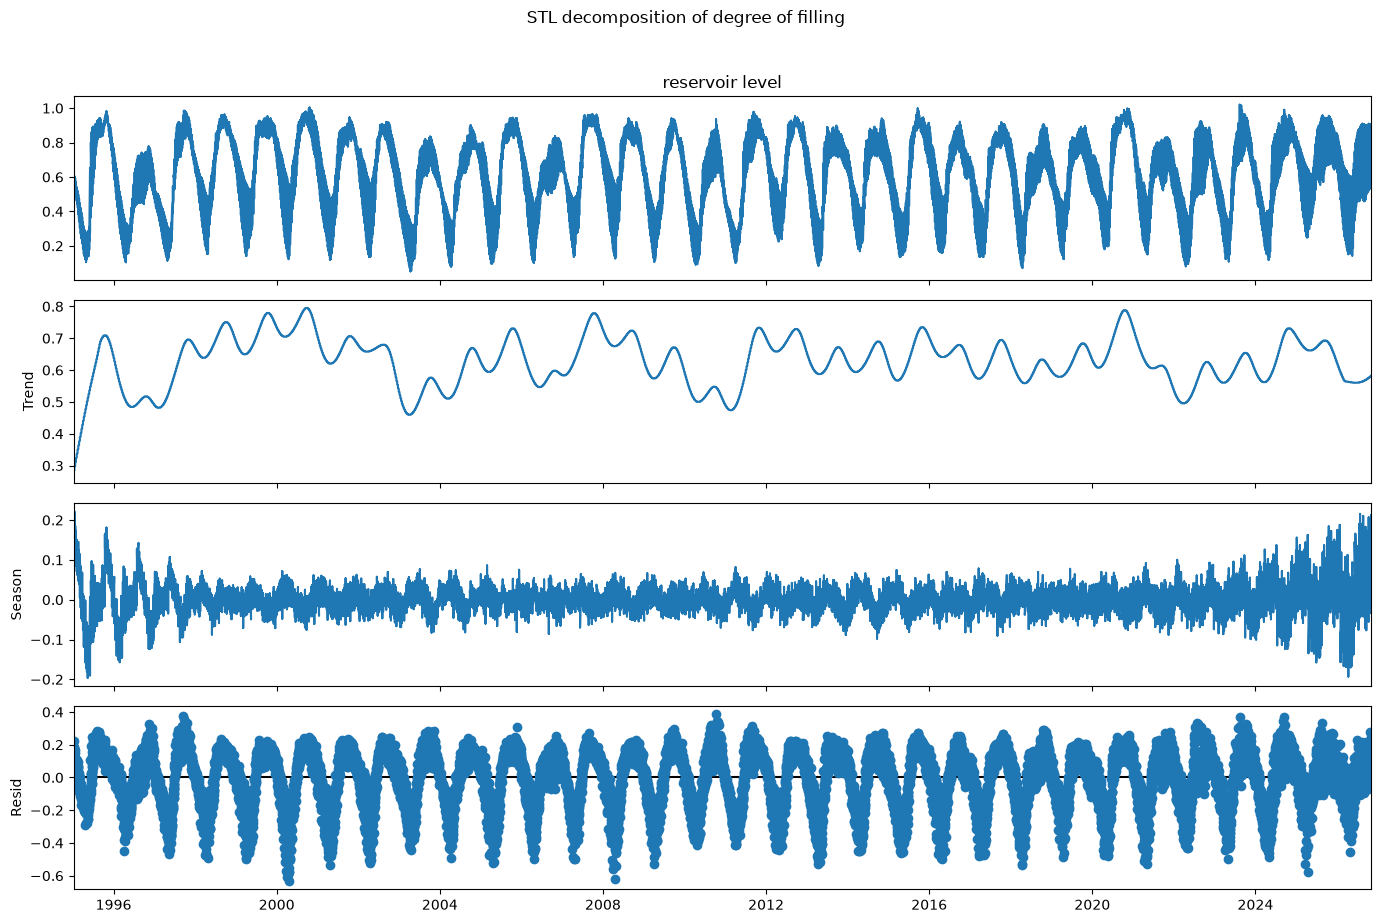

In [34]:
fig = plot_stl(
    data=df_nve,
    seasonal=13,
    trend=None,
    robust=True,
    period=365
)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram


def plot_spectrogram(data, window_length=365, overlap=300):
    # Prepare time series
    series = (
        data.set_index("date")["reservoir level"]
        .sort_index()
        .dropna()
    )

    values = series.to_numpy()

    # Calculate spectrogram
    frequencies, times, power = spectrogram(
        values,
        fs=1,  # One observation per day
        nperseg=window_length,
        noverlap=overlap
    )

    # Plot
    fig, ax = plt.subplots(figsize=(14, 6))

    mesh = ax.pcolormesh(
        times,
        frequencies,
        10 * np.log10(power + 1e-12),
        shading="auto"
    )

    fig.colorbar(mesh, ax=ax, label="Power (dB)")
    ax.set_title("Spectrogram of reservoir level")
    ax.set_xlabel("Time (days from start)")
    ax.set_ylabel("Frequency (cycles per day)")

    plt.tight_layout()

    return fig

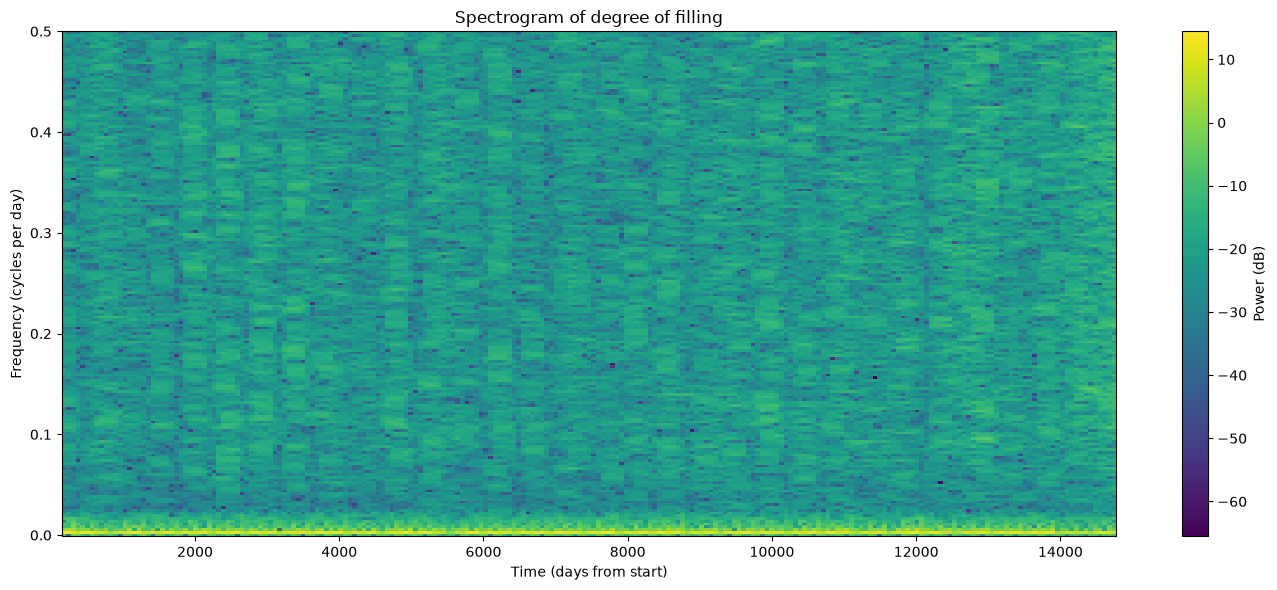

In [38]:
fig = plot_spectrogram(
    data=df_nve,
    window_length=365,
    overlap=300
)

plt.show()

In [39]:
response_df.to_parquet("data_weather/weather_data.parquet", index=False)